In [2]:
#Inisialisasi Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [8]:
#Pemetaan Dataset & Path Gambar
import os
import numpy as np
import pandas as pd

# ==========================================
# 1. ATUR PATH (Sesuaikan nama folder Drive)
# ==========================================
BASE_PATH = "/content/drive/MyDrive/FOLDER TUGAS TPB KELOMPOK 6/Dataset X-Ray"

LABEL_CSV = "/content/drive/MyDrive/FOLDER TUGAS TPB KELOMPOK 6/Dataset X-Ray/boneage-training-dataset.csv"
SPLIT_CSV = "/content/drive/MyDrive/FOLDER TUGAS TPB KELOMPOK 6/Dataset X-Ray/splits.csv"
TRAIN_DIR = "/content/drive/MyDrive/FOLDER TUGAS TPB KELOMPOK 6/Dataset X-Ray/training"

ID_COL = "id"
SPLIT_COL = "split"

# ==========================================
# 2. BACA & PROSES DATAFRAME
# ==========================================
labels = pd.read_csv(LABEL_CSV)
splits = pd.read_csv(SPLIT_CSV)

if ID_COL in labels.columns and ID_COL != "id":
    labels = labels.rename(columns={ID_COL: "id"})

labels["male"] = labels["male"].astype(str).str.lower().map(
    {"true": 1, "false": 0, "1": 1, "0": 0}
).fillna(0).astype(int)

splits_clean = splits[[ID_COL, SPLIT_COL]].rename(columns={ID_COL: "id", SPLIT_COL: "split"})
df = labels.merge(splits_clean, on="id")

df["split"] = df["split"].astype(str).str.lower().replace({"validation": "val", "valid": "val"})
df = df.reset_index(drop=True)

# ==========================================
# 3. PANCINGAN PENCARIAN PATH GAMBAR
# ==========================================
print("Sedang memetakan lokasi seluruh gambar di Drive...")
file_map = {}
for root, _, files in os.walk(TRAIN_DIR):
    for file in files:
        if file.lower().endswith(('.png', '.jpg', '.jpeg')):
            name_no_ext = os.path.splitext(file)[0]
            full_path = os.path.join(root, file)

            # Simpan path baik dengan kunci String maupun Integer
            file_map[name_no_ext] = full_path
            if name_no_ext.isdigit():
                file_map[int(name_no_ext)] = full_path

# Petakan ke dataframe
path_of = {img_id: file_map.get(img_id, file_map.get(str(img_id), None)) for img_id in df["id"]}

# Masking split & target
tr = (df["split"] == "train").values
va = (df["split"] == "val").values
te = (df["split"] == "test").values
y = df["boneage"].values.astype(np.float32)

# Verifikasi
missing_count = sum(1 for p in path_of.values() if p is None)
print(f"Total data: {len(df)} | Gambar ditemukan: {len(df) - missing_count} | Gambar hilang/None: {missing_count}")
print("Contoh sampel path terdeteksi:", path_of[df["id"].iloc[0]])

Sedang memetakan lokasi seluruh gambar di Drive...
Total data: 12611 | Gambar ditemukan: 12611 | Gambar hilang/None: 0
Contoh sampel path terdeteksi: /content/drive/MyDrive/FOLDER TUGAS TPB KELOMPOK 6/Dataset X-Ray/training/1377.png


In [9]:
#Modul & Fungsi Preprocessing Citra
import cv2
import numpy as np

# ==========================================
# KONSTANTA PREPROCESSING
# ==========================================
IMG_SIZE = 224      # Ukuran resolusi standar untuk model Deep Learning
WORK_SIDE = 512     # Ukuran kerja pemrosesan awal

# ==========================================
# FUNGSI-FUNGSI PREPROCESSING
# ==========================================
def fix_inversion(img):
    """Balik citra jika latar (tepi) terang. Heuristik: median piksel tepi > 127."""
    border = np.concatenate([img[:5].ravel(), img[-5:].ravel(), img[:, :5].ravel(), img[:, -5:].ravel()])
    if np.median(border) > 127:
        return 255 - img, 1
    return img, 0

def letterbox(img, size=IMG_SIZE):
    """Resize mempertahankan rasio aspek, sisanya padding hitam."""
    h, w = img.shape
    if h == 0 or w == 0:
        return np.zeros((size, size), np.uint8)

    s = size / max(h, w)
    nh, nw = max(1, round(h * s)), max(1, round(w * s))
    r = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_AREA)
    out = np.zeros((size, size), np.uint8)
    y0, x0 = (size - nh) // 2, (size - nw) // 2
    out[y0:y0 + nh, x0:x0 + nw] = r
    return out

def enhance(img):
    """Normalisasi min-max -> median filter 3x3 -> CLAHE (clip 2.0, tile 8x8)."""
    img = cv2.normalize(img, None, 0, 255, cv2.NORM_MINMAX)
    img = cv2.medianBlur(img, 3)
    return cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(img)

def roi_box(img, margin=0.05, min_area=0.05):
    """Otsu -> morfologi -> komponen terbesar -> bounding box + margin. None jika gagal."""
    blur = cv2.GaussianBlur(img, (5, 5), 0)
    _, m = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))
    m = cv2.morphologyEx(cv2.morphologyEx(m, cv2.MORPH_CLOSE, k), cv2.MORPH_OPEN, k)
    n, _, stats, _ = cv2.connectedComponentsWithStats(m)
    if n < 2:
        return None
    j = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    x, yy, w, h, a = stats[j]
    if a < min_area * img.shape[0] * img.shape[1]:
        return None
    mx, my = int(margin * w), int(margin * h)
    x0, y0 = max(0, x - mx), max(0, yy - my)
    x1, y1 = min(img.shape[1], x + w + mx), min(img.shape[0], yy + h + my)
    return x0, y0, x1, y1

def process_one(path):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise RuntimeError(f"Gagal baca: {path}")
    s = WORK_SIDE / max(img.shape)
    if s < 1:
        img = cv2.resize(img, (round(img.shape[1] * s), round(img.shape[0] * s)), interpolation=cv2.INTER_AREA)
    img, inv = fix_inversion(img)
    enh = enhance(img)
    box = roi_box(img)
    fb = 0
    if box is None:
        box, fb = (0, 0, img.shape[1], img.shape[0]), 1
    x0, y0, x1, y1 = box
    out = {
        "raw": letterbox(img),
        "enh": letterbox(enh),
        "roi": letterbox(img[y0:y1, x0:x1]),
        "enh_roi": letterbox(enh[y0:y1, x0:x1])
    }
    return out, inv, fb

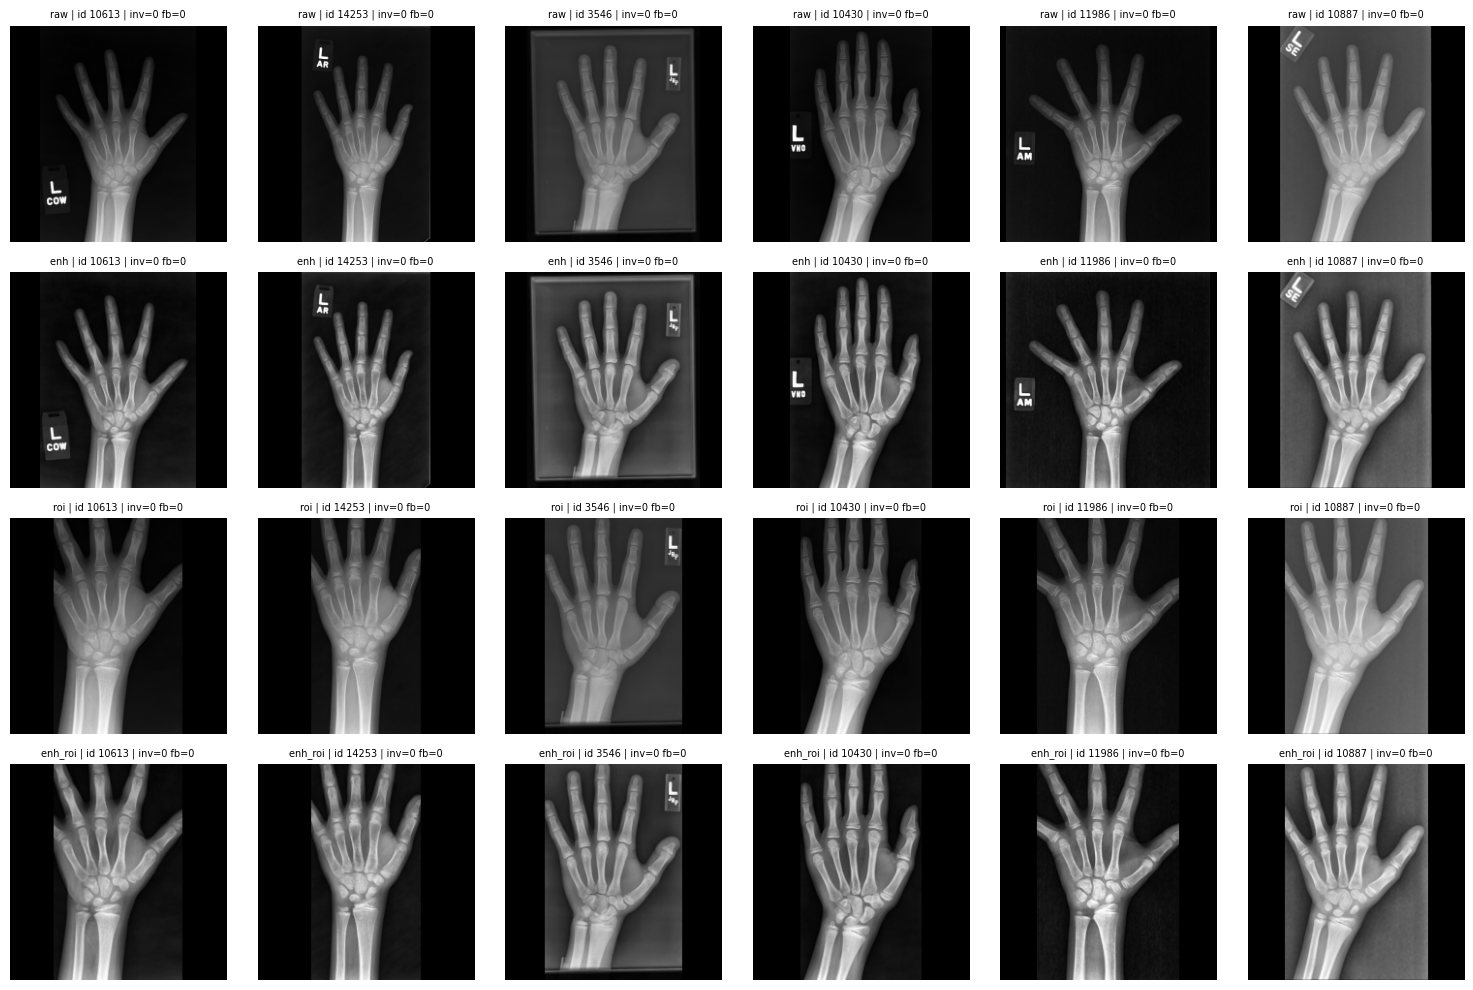

In [10]:
#Visualisasi & Pengujian Preprocessing Sampel
import math
import glob
import shutil
import matplotlib.pyplot as plt
from tqdm import tqdm
from concurrent.futures import ThreadPoolExecutor

# ==========================================
# KONFIGURASI KONSTANTA & PATH FOLDER
# ==========================================
SEED = 42
VARIANTS = ["raw", "enh", "roi", "enh_roi"]

# Path disesuaikan dengan struktur Google Drive Anda
DRIVE_CACHE = "/content/drive/MyDrive/FOLDER TUGAS TPB KELOMPOK 6/cache"
CACHE_DIR = "/content/cache"
FEAT_DIR = "/content/features"
OUT_DIR = "/content/output"

# Buat folder jika belum ada
for d in [DRIVE_CACHE, CACHE_DIR, FEAT_DIR, OUT_DIR]:
    os.makedirs(d, exist_ok=True)

# ==========================================
# VISUALISASI SAMPEL GAMBAR
# ==========================================
np.random.seed(SEED)
smp = np.random.RandomState(SEED).choice(len(df), 6, replace=False)
res = [process_one(path_of[df["id"].iloc[i]]) for i in smp]

fig, ax = plt.subplots(4, 6, figsize=(15, 10))
for j, (o, inv, fb) in enumerate(res):
    for r, v in enumerate(VARIANTS):
        ax[r, j].imshow(o[v], cmap="gray")
        ax[r, j].axis("off")
        ax[r, j].set_title(f"{v} | id {df['id'].iloc[smp[j]]} | inv={inv} fb={fb}", fontsize=7)

plt.tight_layout()
plt.show()

In [13]:
#Pemrosesan Masal & Pembuatan Cache Data
CHUNK = 1000
N_WORKERS = 4

ids = df["id"].values
paths = [path_of[i] for i in ids]
nchunks = math.ceil(len(ids) / CHUNK)

# Pulihkan cache dari Drive jika ada
for f in glob.glob(os.path.join(DRIVE_CACHE, "chunk_*.npz")):
    dst = os.path.join(CACHE_DIR, os.path.basename(f))
    if not os.path.exists(dst):
        shutil.copy(f, dst)

# Proses pemrosesan massal per chunk
for k in tqdm(range(nchunks), desc="Processing Chunks"):
    f = os.path.join(CACHE_DIR, f"chunk_{k:03d}.npz")
    if os.path.exists(f):
        continue
    with ThreadPoolExecutor(N_WORKERS) as ex:
        res = list(ex.map(process_one, paths[k * CHUNK:(k + 1) * CHUNK]))

    np.savez(f, **{v: np.stack([r[0][v] for r in res]) for v in VARIANTS},
             inv=np.array([r[1] for r in res]), fb=np.array([r[2] for r in res]))
    shutil.copy(f, DRIVE_CACHE)

# Gabungkan hasil dari seluruh chunk
parts = [np.load(os.path.join(CACHE_DIR, f"chunk_{k:03d}.npz")) for k in range(nchunks)]
X = {v: np.concatenate([p[v] for p in parts]) for v in VARIANTS}
inv_flag = np.concatenate([p["inv"] for p in parts])
fb_flag = np.concatenate([p["fb"] for p in parts])

print("\nShape dari tiap varian:", {v: X[v].shape for v in VARIANTS})
print(f"Citra dibalik: {inv_flag.sum()} ({inv_flag.mean()*100:.1f}%) | ROI gagal (pakai citra penuh): {fb_flag.sum()} ({fb_flag.mean()*100:.1f}%)")

Processing Chunks: 100%|██████████| 13/13 [32:12<00:00, 148.64s/it]



Shape dari tiap varian: {'raw': (12611, 224, 224), 'enh': (12611, 224, 224), 'roi': (12611, 224, 224), 'enh_roi': (12611, 224, 224)}
Citra dibalik: 446 (3.5%) | ROI gagal (pakai citra penuh): 296 (2.3%)


In [14]:
#Setup Neural Network & Ekstraksi Fitur
import torch
import torch.nn as nn
from torchvision import models as M
from scipy.stats import pearsonr
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

torch.manual_seed(SEED)
dev = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", dev)

def get_backbone(name):
    if name == "resnet50":
        m = M.resnet50(weights=M.ResNet50_Weights.IMAGENET1K_V2)
        m.fc = nn.Identity()
    elif name == "densenet121":
        m = M.densenet121(weights=M.DenseNet121_Weights.IMAGENET1K_V1)
        m.classifier = nn.Identity()
    elif name == "efficientnet_b0":
        m = M.efficientnet_b0(weights=M.EfficientNet_B0_Weights.IMAGENET1K_V1)
        m.classifier = nn.Identity()
    return m.to(dev).eval()

MEAN = torch.tensor([0.485, 0.456, 0.406], device=dev).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225], device=dev).view(1, 3, 1, 1)

@torch.no_grad()
def extract_feats(backbone, variant, bs=128):
    f = os.path.join(FEAT_DIR, f"{backbone}_{variant}.npy")
    if os.path.exists(f):
        return np.load(f)
    model = get_backbone(backbone)
    out = []
    for i in tqdm(range(0, len(X[variant]), bs), desc=f"Extracting {backbone}/{variant}"):
        xb = torch.from_numpy(X[variant][i:i + bs]).to(dev).float().div(255).unsqueeze(1).expand(-1, 3, -1, -1)
        xb = (xb - MEAN) / STD
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(dev == "cuda")):
            out.append(model(xb).float().cpu().numpy())
    F = np.concatenate(out).astype(np.float32)
    np.save(f, F)
    return F

def metrics(yt, yp):
    return {
        "MAE": mean_absolute_error(yt, yp),
        "RMSE": mean_squared_error(yt, yp) ** 0.5,
        "R2": r2_score(yt, yp),
        "Pearson": pearsonr(yt, yp)[0]
    }

base = y[tr].mean()
print(f"Baseline MAE val {mean_absolute_error(y[va], np.full(va.sum(), base)):.1f} | test {mean_absolute_error(y[te], np.full(te.sum(), base)):.1f}")

Device: cuda
Baseline MAE val 33.8 | test 33.6


In [15]:
#Pipeline Model Regresi & Fungsi Pengujian
from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from xgboost import XGBRegressor

male = df["male"].values.astype(np.float32).reshape(-1, 1)

def prepare(F, pca_dim=None):
    sc = StandardScaler().fit(F[tr])
    Z = sc.transform(F)
    if pca_dim:
        Z = PCA(pca_dim, random_state=SEED).fit(Z[tr]).transform(Z)
    return np.hstack([Z, male]).astype(np.float32)

def fit_predict(name, Xf):
    mu, sd = y[tr].mean(), y[tr].std()
    ys = (y[tr] - mu) / sd
    if name == "ridge":
        best = None
        for a in [1, 10, 100, 1000, 3000, 10000]:
            m = Ridge(alpha=a).fit(Xf[tr], ys)
            e = mean_absolute_error(y[va], m.predict(Xf[va]) * sd + mu)
            if best is None or e < best[0]:
                best = (e, m, a)
        m, par = best[1], {"alpha": best[2]}
    elif name == "svr":
        m, par = SVR(kernel="rbf", C=10, epsilon=0.1).fit(Xf[tr], ys), {"C": 10, "eps": 0.1}
    elif name == "rf":
        m = RandomForestRegressor(300, min_samples_leaf=3, max_features=0.3, n_jobs=-1, random_state=SEED).fit(Xf[tr], ys)
        par = {"trees": 300}
    elif name == "xgb":
        m = XGBRegressor(n_estimators=1000, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.5,
                         tree_method="hist", random_state=SEED, early_stopping_rounds=50)
        m.fit(Xf[tr], ys, eval_set=[(Xf[va], (y[va] - mu) / sd)], verbose=False)
        par = {"best_iter": int(m.best_iteration)}
    return m.predict(Xf[va]) * sd + mu, m.predict(Xf[te]) * sd + mu, par

results = []
def run(backbone, variant, reg, pca_dim=None):
    Xf = prepare(extract_feats(backbone, variant), pca_dim)
    pv, pt, par = fit_predict(reg, Xf)
    mv, mt = metrics(y[va], pv), metrics(y[te], pt)
    row = {
        "backbone": backbone, "variant": variant, "regressor": reg, "pca": pca_dim, "params": str(par),
        **{f"val_{k}": v for k, v in mv.items()}, **{f"test_{k}": v for k, v in mt.items()}
    }
    results.append(row)
    print(f"{backbone:16s}{variant:8s}{reg:6s} val MAE {mv['MAE']:.1f} | test MAE {mt['MAE']:.1f}")
    return pv, pt

In [16]:
#Studi Ablasi Varian Preprocessing
results = []  # Reset list hasil eksperimen
for v in VARIANTS:
    for reg in ["ridge", "svr"]:
        run("resnet50", v, reg)

abl = pd.DataFrame(results)
print("\n--- Hasil Ablasi Preprocessing ---")
print(abl[["variant", "regressor", "val_MAE", "test_MAE", "test_RMSE", "test_R2", "test_Pearson"]].round(2))

best_variant = abl[abl.regressor == "svr"].sort_values("val_MAE").iloc[0]["variant"]
print("\nVarian terbaik (berdasarkan val MAE, SVR):", best_variant)
abl.to_csv(os.path.join(OUT_DIR, "ablation_preprocessing.csv"), index=False)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 166MB/s]
Extracting resnet50/raw: 100%|██████████| 99/99 [00:20<00:00,  4.86it/s]


resnet50        raw     ridge  val MAE 14.3 | test MAE 14.1
resnet50        raw     svr    val MAE 15.4 | test MAE 15.0


Extracting resnet50/enh: 100%|██████████| 99/99 [00:17<00:00,  5.63it/s]


resnet50        enh     ridge  val MAE 14.1 | test MAE 14.5
resnet50        enh     svr    val MAE 15.1 | test MAE 14.9


Extracting resnet50/roi: 100%|██████████| 99/99 [00:17<00:00,  5.65it/s]


resnet50        roi     ridge  val MAE 13.6 | test MAE 13.8
resnet50        roi     svr    val MAE 15.0 | test MAE 14.6


Extracting resnet50/enh_roi: 100%|██████████| 99/99 [00:17<00:00,  5.63it/s]


resnet50        enh_roi ridge  val MAE 13.8 | test MAE 13.9
resnet50        enh_roi svr    val MAE 15.1 | test MAE 14.5

--- Hasil Ablasi Preprocessing ---
   variant regressor  val_MAE  test_MAE  test_RMSE  test_R2  test_Pearson
0      raw     ridge    14.27     14.14      18.16     0.80          0.90
1      raw       svr    15.39     15.02      19.71     0.77          0.88
2      enh     ridge    14.13     14.47      18.41     0.80          0.89
3      enh       svr    15.08     14.91      19.32     0.78          0.88
4      roi     ridge    13.61     13.79      18.01     0.81          0.90
5      roi       svr    14.99     14.63      19.38     0.78          0.88
6  enh_roi     ridge    13.76     13.86      17.92     0.81          0.90
7  enh_roi       svr    15.13     14.47      18.87     0.79          0.89

Varian terbaik (berdasarkan val MAE, SVR): roi


In [6]:
import os
import gc
import torch
import torch.nn as nn
from torchvision import models as M
from tqdm import tqdm
import numpy as np
import pandas as pd
from xgboost import XGBRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import pearsonr

# ==========================================
# 0. RECOVERY DATAFRAME & CACHE (Tahan Restart)
# ==========================================
SEED = 42
dev = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(SEED)

BASE_PATH = "/content/drive/MyDrive/FOLDER TUGAS TPB KELOMPOK 6/Dataset X-Ray"
LABEL_CSV = f"{BASE_PATH}/boneage-training-dataset.csv"
SPLIT_CSV = f"{BASE_PATH}/splits.csv"
DRIVE_CACHE = "/content/drive/MyDrive/FOLDER TUGAS TPB KELOMPOK 6/cache"
CACHE_DIR = "/content/cache"
FEAT_DIR = "/content/features"
OUT_DIR = "/content/output"

for d in [FEAT_DIR, OUT_DIR, CACHE_DIR]:
    os.makedirs(d, exist_ok=True)

# Re-load Dataframe
labels = pd.read_csv(LABEL_CSV)
splits = pd.read_csv(SPLIT_CSV)
if "id" not in labels.columns and "id" in splits.columns:
    labels = labels.rename(columns={splits.columns[0]: "id"})

labels["male"] = labels["male"].astype(str).str.lower().map({"true": 1, "false": 0, "1": 1, "0": 0}).fillna(0).astype(int)
splits_clean = splits[["id", "split"]].rename(columns={"split": "split"})
df = labels.merge(splits_clean, on="id")
df["split"] = df["split"].astype(str).str.lower().replace({"validation": "val", "valid": "val"})
df = df.reset_index(drop=True)

tr = (df["split"] == "train").values
va = (df["split"] == "val").values
te = (df["split"] == "test").values
y = df["boneage"].values.astype(np.float32)
male = df["male"].values.astype(np.float32).reshape(-1, 1)

# Re-load Variabel Gambar 'X' dari Cache .npz
if 'X' not in globals():
    print("Memuat kembali cache citra (.npz) dari Drive/Cache...")
    import glob, shutil
    for f in glob.glob(os.path.join(DRIVE_CACHE, "chunk_*.npz")):
        dst = os.path.join(CACHE_DIR, os.path.basename(f))
        if not os.path.exists(dst):
            shutil.copy(f, dst)

    cache_files = sorted(glob.glob(os.path.join(CACHE_DIR, "chunk_*.npz")))
    if len(cache_files) == 0:
        cache_files = sorted(glob.glob(os.path.join(DRIVE_CACHE, "chunk_*.npz")))

    parts = [np.load(f) for f in cache_files]
    VARIANTS = ["raw", "enh", "roi", "enh_roi"]
    X = {v: np.concatenate([p[v] for p in parts]) for v in VARIANTS}
    print("Berhasil memuat cache citra!")

# ==========================================
# 1. SETUP EKSTRAKSI & METRIKS
# ==========================================
def get_backbone(name):
    if name == "resnet50":
        m = M.resnet50(weights=M.ResNet50_Weights.IMAGENET1K_V2); m.fc = nn.Identity()
    elif name == "densenet121":
        m = M.densenet121(weights=M.DenseNet121_Weights.IMAGENET1K_V1); m.classifier = nn.Identity()
    elif name == "efficientnet_b0":
        m = M.efficientnet_b0(weights=M.EfficientNet_B0_Weights.IMAGENET1K_V1); m.classifier = nn.Identity()
    return m.to(dev).eval()

MEAN = torch.tensor([0.485, 0.456, 0.406], device=dev).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225], device=dev).view(1, 3, 1, 1)

@torch.no_grad()
def extract_feats(backbone, variant, bs=128):
    f = os.path.join(FEAT_DIR, f"{backbone}_{variant}.npy")
    if os.path.exists(f): return np.load(f)
    model = get_backbone(backbone)
    out = []
    for i in tqdm(range(0, len(X[variant]), bs), desc=f"Extracting {backbone}/{variant}"):
        xb = torch.from_numpy(X[variant][i:i + bs]).to(dev).float().div(255).unsqueeze(1).expand(-1, 3, -1, -1)
        xb = (xb - MEAN) / STD
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(dev == "cuda")):
            out.append(model(xb).float().cpu().numpy())
    F = np.concatenate(out).astype(np.float32)
    np.save(f, F)
    return F

results = []
best_variant = "roi"

def metrics(yt, yp):
    return {"MAE": mean_absolute_error(yt, yp), "RMSE": mean_squared_error(yt, yp) ** 0.5,
            "R2": r2_score(yt, yp), "Pearson": pearsonr(yt, yp)[0]}

def prepare(F, pca_dim=None):
    sc = StandardScaler().fit(F[tr])
    Z = sc.transform(F)
    if pca_dim:
        from sklearn.decomposition import PCA
        Z = PCA(pca_dim, random_state=SEED).fit(Z[tr]).transform(Z)
    return np.hstack([Z, male]).astype(np.float32)

def fit_predict_fast(name, Xf):
    mu, sd = y[tr].mean(), y[tr].std()
    ys = (y[tr] - mu) / sd
    if name == "ridge":
        best = None
        for a in [1, 10, 100, 1000, 3000, 10000]:
            m = Ridge(alpha=a).fit(Xf[tr], ys)
            e = mean_absolute_error(y[va], m.predict(Xf[va]) * sd + mu)
            if best is None or e < best[0]: best = (e, m, a)
        m, par = best[1], {"alpha": best[2]}
    elif name == "svr":
        m, par = SVR(kernel="rbf", C=10, epsilon=0.1).fit(Xf[tr], ys), {"C": 10, "eps": 0.1}
    return m.predict(Xf[va]) * sd + mu, m.predict(Xf[te]) * sd + mu, par

def run_standalone(backbone, variant, reg, pca_dim=None):
    Xf = prepare(extract_feats(backbone, variant), pca_dim)
    pv, pt, par = fit_predict_fast(reg, Xf)
    mv, mt = metrics(y[va], pv), metrics(y[te], pt)
    row = {
        "backbone": backbone, "variant": variant, "regressor": reg, "pca": pca_dim, "params": str(par),
        **{f"val_{k}": v for k, v in mv.items()}, **{f"test_{k}": v for k, v in mt.items()}
    }
    results.append(row)
    print(f"{backbone:16s}{variant:8s}{reg:6s} val MAE {mv['MAE']:.1f} | test MAE {mt['MAE']:.1f}")

# ==========================================
# 2. RUNNING METODE PADA VARIAN TERBAIK
# ==========================================
print(f"Memulai evaluasi dengan Varian Terbaik: '{best_variant}'\n")

for b in ["resnet50", "densenet121", "efficientnet_b0"]:
    for reg in ["ridge", "svr"]:
        run_standalone(b, best_variant, reg)
        gc.collect()

bb_df = pd.DataFrame([r for r in results if r["variant"] == best_variant and r["regressor"] in ("ridge", "svr")])
best_bb = bb_df[bb_df.regressor == "svr"].sort_values("val_MAE").iloc[0]["backbone"]
print("\nBackbone terbaik terdeteksi:", best_bb)

# XGBoost Hemat RAM
Xf_xgb = prepare(extract_feats(best_bb, best_variant), pca_dim=64)
mu, sd = y[tr].mean(), y[tr].std()
ys = (y[tr] - mu) / sd

m_xgb = XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, tree_method="hist", n_jobs=2, random_state=SEED)
m_xgb.fit(Xf_xgb[tr], ys)

pv_xgb, pt_xgb = m_xgb.predict(Xf_xgb[va]) * sd + mu, m_xgb.predict(Xf_xgb[te]) * sd + mu
mv_xgb, mt_xgb = metrics(y[va], pv_xgb), metrics(y[te], pt_xgb)

results.append({
    "backbone": best_bb, "variant": best_variant, "regressor": "xgb", "pca": 64, "params": "{'n_est': 100}",
    **{f"val_{k}": v for k, v in mv_xgb.items()}, **{f"test_{k}": v for k, v in mt_xgb.items()}
})
print(f"{best_bb:16s}{best_variant:8s}xgb    val MAE {mv_xgb['MAE']:.1f} | test MAE {mt_xgb['MAE']:.1f}")

# ==========================================
# 3. CETAK HASIL & SIMPAN
# ==========================================
cmp = pd.DataFrame([r for r in results if r["variant"] == best_variant])
print("\n--- Perbandingan Semua Model pada Varian Terbaik ---")
print(cmp[["backbone", "regressor", "pca", "val_MAE", "test_MAE", "test_RMSE", "test_R2", "test_Pearson"]].round(2))

pd.DataFrame(results).to_csv(os.path.join(OUT_DIR, "semua_hasil.csv"), index=False)

Memuat kembali cache citra (.npz) dari Drive/Cache...
Berhasil memuat cache citra!
Memulai evaluasi dengan Varian Terbaik: 'roi'



Extracting resnet50/roi: 100%|██████████| 99/99 [00:17<00:00,  5.72it/s]


resnet50        roi     ridge  val MAE 13.6 | test MAE 13.8
resnet50        roi     svr    val MAE 15.0 | test MAE 14.6
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 169MB/s]
Extracting densenet121/roi: 100%|██████████| 99/99 [00:17<00:00,  5.53it/s]


densenet121     roi     ridge  val MAE 12.0 | test MAE 12.3
densenet121     roi     svr    val MAE 12.2 | test MAE 11.9
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 173MB/s]
Extracting efficientnet_b0/roi: 100%|██████████| 99/99 [00:09<00:00, 10.34it/s]


efficientnet_b0 roi     ridge  val MAE 13.2 | test MAE 12.8
efficientnet_b0 roi     svr    val MAE 13.7 | test MAE 12.9

Backbone terbaik terdeteksi: densenet121
densenet121     roi     xgb    val MAE 15.9 | test MAE 15.7

--- Perbandingan Semua Model pada Varian Terbaik ---
          backbone regressor   pca  val_MAE  test_MAE  test_RMSE  test_R2  \
0         resnet50     ridge   NaN    13.61     13.79      18.01     0.81   
1         resnet50       svr   NaN    14.99     14.63      19.38     0.78   
2      densenet121     ridge   NaN    12.00     12.31      15.99     0.85   
3      densenet121       svr   NaN    12.19     11.86      15.56     0.86   
4  efficientnet_b0     ridge   NaN    13.17     12.85      17.10     0.83   
5  efficientnet_b0       svr   NaN    13.72     12.88      17.41     0.82   
6      densenet121       xgb  64.0    15.87     15.73      20.35     0.75   

   test_Pearson  
0          0.90  
1          0.88  
2          0.92  
3          0.93  
4          0.91  

In [9]:
# ==========================================
# UJI COBA: WEIGHTED ENSEMBLE BLENDING
# ==========================================
# Extract fitur 3 backbone utama pada varian ROI
F_dense = extract_feats("densenet121", "roi")
F_res   = extract_feats("resnet50", "roi")
F_eff   = extract_feats("efficientnet_b0", "roi")

# Fitur + Gender
X_dense = prepare(F_dense)
X_res   = prepare(F_res)
X_eff   = prepare(F_eff)

# Model SVR masing-masing backbone
mu, sd = y[tr].mean(), y[tr].std()
ys = (y[tr] - mu) / sd

m_dense = SVR(kernel="rbf", C=10, epsilon=0.1).fit(X_dense[tr], ys)
m_res   = SVR(kernel="rbf", C=10, epsilon=0.1).fit(X_res[tr], ys)
m_eff   = SVR(kernel="rbf", C=10, epsilon=0.1).fit(X_eff[tr], ys)

# Prediksi pada Test Set
pred_dense = m_dense.predict(X_dense[te]) * sd + mu
pred_res   = m_res.predict(X_res[te]) * sd + mu
pred_eff   = m_eff.predict(X_eff[te]) * sd + mu

# Weighted Averaging (Bobot disesuaikan performa)
pred_ensemble = (0.50 * pred_dense) + (0.30 * pred_res) + (0.20 * pred_eff)

mae_ensemble = mean_absolute_error(y[te], pred_ensemble)
print(f"MAE Weighted Ensemble (Test Set): {mae_ensemble:.2f} bulan")

MAE Weighted Ensemble (Test Set): 11.47 bulan
